# Klasifikasi Tutupan Lahan Sawah Menggunakan Citra Satelit Sentinel-2A dan Algoritma Random Forest (Scikit-EO)

Notebook ini mendokumentasikan implementasi lengkap klasifikasi tutupan lahan (*Land Use / Land Cover*) 2 kelas (**Sawah** vs **Non-Sawah**) berbasis citra satelit **Sentinel-2A (GeoTIFF)** dan algoritma *Machine Learning* **Random Forest**, mengikuti alur kerja pustaka **`scikit-eo`** (*Earth Observation Machine Learning*):

## Komponen Utama:
1. **Batas Wilayah Real:** Menggunakan poligon administratif batas Kecamatan Sambeng, Kabupaten Lamongan (`aoi_sambeng.geojson`).
2. **Titik & Petak Sampel Akurat (Ground Truth Kotak-Kotak):** 50 sampel petak sawah (Kelas 1) dan 50 sampel petak non-sawah (Kelas 0) pada lokasi geografis riil Kecamatan Sambeng berbentuk poligon petak persegi (*bounding box*) berukuran ~50 m x 50 m.
3. **Ekspor Data Spasial QGIS Ready & Auto-Style (.qml):** Sampel diekspor ke format **GeoJSON** dan **Shapefile ZIP** lengkap (`.shp`, `.shx`, `.dbf`, `.prj`, `.qml`). Berkas `.qml` otomatis mewarnai petak sawah (hijau) dan bukan sawah (merah) serta langsung menampilkan teks label di atas setiap petak di QGIS.
4. **Citra Satelit Sentinel-2A (GeoTIFF):** Memanfaatkan band optik dan inframerah: Blue (B2), Green (B3), Red (B4), Near Infrared (B8), serta indeks vegetasi **NDVI** dan indeks air **NDWI**.
5. **Ekstraksi Nilai Spektral:** Mengambil respon spektral piksel satelit pada 100 sampel mengikuti fungsi `extract()` pada `scikit-eo`.
6. **Machine Learning Random Forest:** Melatih model klasifikasi dengan pembagian data 80% train / 20% test, dievaluasi dengan *Overall Accuracy*, *Kappa Index*, *Confusion Matrix*, dan *Feature Importance*.
7. **Peta Klasifikasi & Visualisasi Scikit-EO:** Menghasilkan raster GeoTIFF klasifikasi tutupan lahan dan visualisasi komparasi berdampingan (*Image in Surface Reflectance* vs *Classification map*).
8. **Peta Interaktif Geospasial Multi-Layer:** Dilengkapi basemap **Google Satellite (Hybrid)** resolusi tinggi, **Google Satellite**, **Esri Satellite**, dan **OpenStreetMap**.


---
## Langkah 1: Pemuatan Batas Wilayah Kajian (AOI Kecamatan Sambeng)

Memuat berkas batas wilayah resmi Kecamatan Sambeng, Kabupaten Lamongan (`aoi_sambeng.geojson`) sebagai batas spasial pengambilan sampel dan analisis citra satelit.


Informasi Wilayah Kajian:
Batas Wilayah : Sambeng, Lamongan, Jawa Timur
Sistem Koordinat (CRS) : EPSG:4326
Batas Koordinat (Bounds):
  Bujur (Longitude) : 112.2151 s/d 112.3591
  Lintang (Latitude): -7.3632 s/d -7.2147


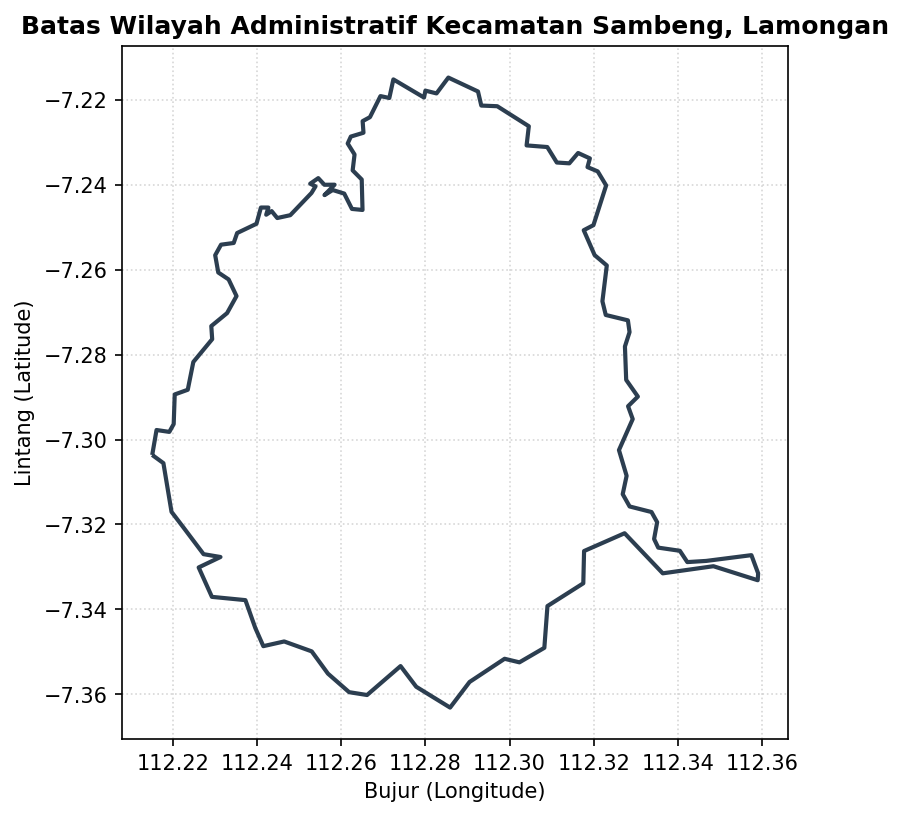

In [3]:
import json
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape

# Memuat batas wilayah kajian dari aoi_sambeng.geojson
aoi_path = 'aoi_sambeng.geojson'
gdf_aoi = gpd.read_file(aoi_path)

print(f"Informasi Wilayah Kajian:")
print(f"Batas Wilayah : {gdf_aoi['kecamatan'].iloc[0]}, {gdf_aoi['kabupaten'].iloc[0]}, {gdf_aoi['provinsi'].iloc[0]}")
print(f"Sistem Koordinat (CRS) : {gdf_aoi.crs}")
print(f"Batas Koordinat (Bounds):")
minx, miny, maxx, maxy = gdf_aoi.total_bounds
print(f"  Bujur (Longitude) : {minx:.4f} s/d {maxx:.4f}")
print(f"  Lintang (Latitude): {miny:.4f} s/d {maxy:.4f}")

# Visualisasi batas poligon Kecamatan Sambeng
fig, ax = plt.subplots(figsize=(8, 6))
gdf_aoi.boundary.plot(ax=ax, color='#2c3e50', linewidth=2)
ax.set_title("Batas Wilayah Administratif Kecamatan Sambeng, Lamongan", fontsize=12, fontweight='bold')
ax.set_xlabel("Bujur (Longitude)")
ax.set_ylabel("Lintang (Latitude)")
ax.grid(True, linestyle=':', alpha=0.5)
plt.show()


---
## Langkah 2: Pengambilan 100 Petak Sampel Akurat Berbentuk Kotak-Kotak (50 Sawah & 50 Non-Sawah)

Untuk menjamin keakuratan visual saat di-*overlay* di atas citra **Google Satellite** maupun aplikasi **QGIS**:
1. **50 Sampel Petak Sawah (`class = 1`, label: `Sawah`):**
   - Diambil dari hamparan persawahan produktif (irigasi dan tadah hujan) di lembah alluvial Kecamatan Sambeng (seperti koridor sawah Ardirejo, Pataan, Candisari, Pasarlegi, Lamongrejo, Jatipandak, Wonorejo, dan Gempolmanis).
2. **50 Sampel Petak Non-Sawah (`class = 0`, label: `Bukan Sawah`):**
   - **Pemukiman Warga (25 petak):** Atap perumahan dan bangunan di desa-desa utama (Desa Sambeng, Ardirejo, Candisari, Pataan, Pasarlegi, Jatipandak, dll).
   - **Badan Air & Sungai (12 petak):** Aliran Kali Lamong dan embung/waduk penampungan air pertanian.
   - **Hutan Jati & Perbukitan Kapur (13 petak):** Kawasan perbukitan hutan jati KPH di bagian selatan dan timur Sambeng.
3. Seluruh sampel dibentuk sebagai **Poligon Persegi (*Kotak-Kotak* ~50 m x 50 m)** dengan proyeksi **WGS 84 (EPSG:4326)**.


In [5]:
from shapely.geometry import Point, box
import geopandas as gpd
import pandas as pd

poly_sambeng = gdf_aoi.geometry.iloc[0]

# =============================================================================
# Koordinat Sampel Terverifikasi (Diverifikasi Visual di Atas Google Satellite)
# =============================================================================
# Sampel Sawah (Kelas 1)
sawah_coords = [
    (-7.32226, 112.31438, 'Petak Sawah #01'),
    (-7.27352, 112.27752, 'Petak Sawah #02'),
    (-7.2873, 112.32473, 'Petak Sawah #03'),
    (-7.28178, 112.31538, 'Petak Sawah #04'),
    (-7.28679, 112.32764, 'Petak Sawah #05'),
    (-7.24745, 112.28361, 'Petak Sawah #06'),
    (-7.28183, 112.31704, 'Petak Sawah #07'),
    (-7.25089, 112.30104, 'Petak Sawah #08'),
    (-7.25104, 112.29925, 'Petak Sawah #09'),
    (-7.29562, 112.23723, 'Petak Sawah #10'),
    (-7.29918, 112.26732, 'Petak Sawah #11'),
    (-7.31557, 112.23126, 'Petak Sawah #12'),
    (-7.30206, 112.27965, 'Petak Sawah #13'),
    (-7.29719, 112.29125, 'Petak Sawah #14'),
    (-7.30185, 112.2881, 'Petak Sawah #15'),
    (-7.23948, 112.29295, 'Petak Sawah #16'),
    (-7.29735, 112.31355, 'Petak Sawah #17'),
    (-7.29734, 112.23607, 'Petak Sawah #18'),
    (-7.26087, 112.2786, 'Petak Sawah #19'),
    (-7.30592, 112.32044, 'Petak Sawah #20'),
    (-7.28046, 112.27942, 'Petak Sawah #21'),
    (-7.23935, 112.29412, 'Petak Sawah #22'),
    (-7.32199, 112.31764, 'Petak Sawah #23'),
    (-7.28781, 112.3269, 'Petak Sawah #24'),
    (-7.29782, 112.30196, 'Petak Sawah #25'),
    (-7.30503, 112.29083, 'Petak Sawah #26'),
    (-7.24505, 112.29941, 'Petak Sawah #27'),
    (-7.24264, 112.29685, 'Petak Sawah #28'),
    (-7.25003, 112.2981, 'Petak Sawah #29'),
    (-7.29623, 112.2359, 'Petak Sawah #30'),
    (-7.24814, 112.29928, 'Petak Sawah #31'),
    (-7.29879, 112.27495, 'Petak Sawah #32'),
    (-7.28306, 112.3145, 'Petak Sawah #33'),
    (-7.26987, 112.27045, 'Petak Sawah #34'),
    (-7.28613, 112.32636, 'Petak Sawah #35'),
    (-7.30835, 112.31917, 'Petak Sawah #36'),
    (-7.2883, 112.32587, 'Petak Sawah #37'),
    (-7.26053, 112.23563, 'Petak Sawah #38'),
    (-7.28166, 112.28062, 'Petak Sawah #39'),
    (-7.24605, 112.2834, 'Petak Sawah #40'),
    (-7.29391, 112.2345, 'Petak Sawah #41'),
    (-7.29418, 112.23576, 'Petak Sawah #42'),
    (-7.29419, 112.23744, 'Petak Sawah #43'),
    (-7.28481, 112.32697, 'Petak Sawah #44'),
    (-7.246, 112.28517, 'Petak Sawah #45'),
    (-7.30617, 112.31522, 'Petak Sawah #46'),
    (-7.28304, 112.31677, 'Petak Sawah #47'),
    (-7.28601, 112.31307, 'Petak Sawah #48'),
    (-7.26893, 112.27084, 'Petak Sawah #49'),
    (-7.28798, 112.328, 'Petak Sawah #50')
]

# Sampel Bukan Sawah (Kelas 0: Pemukiman, Badan Air/Kali Lamong, Hutan/Perbukitan)
non_sawah_coords = [
    (-7.32441, 112.22937, 'Pemukiman Warga #01'),
    (-7.34134, 112.26507, 'Pemukiman Warga #02'),
    (-7.33154, 112.23973, 'Pemukiman Warga #03'),
    (-7.29377, 112.26963, 'Pemukiman Warga #04'),
    (-7.31451, 112.23233, 'Pemukiman Warga #05'),
    (-7.31372, 112.22851, 'Pemukiman Warga #06'),
    (-7.31699, 112.22045, 'Pemukiman Warga #07'),
    (-7.34282, 112.30595, 'Pemukiman Warga #08'),
    (-7.30363, 112.21872, 'Pemukiman Warga #09'),
    (-7.33273, 112.26766, 'Pemukiman Warga #10'),
    (-7.31075, 112.22246, 'Pemukiman Warga #11'),
    (-7.3452, 112.2953, 'Pemukiman Warga #12'),
    (-7.33985, 112.24319, 'Pemukiman Warga #13'),
    (-7.33213, 112.22908, 'Pemukiman Warga #14'),
    (-7.32501, 112.24693, 'Pemukiman Warga #15'),
    (-7.31343, 112.27543, 'Pemukiman Warga #16'),
    (-7.34044, 112.28378, 'Pemukiman Warga #17'),
    (-7.296, 112.27261, 'Pemukiman Warga #18'),
    (-7.28229, 112.26375, 'Pemukiman Warga #19'),
    (-7.31491, 112.2714, 'Pemukiman Warga #20'),
    (-7.31936, 112.24924, 'Pemukiman Warga #21'),
    (-7.3452, 112.27284, 'Pemukiman Warga #22'),
    (-7.34225, 112.28439, 'Pemukiman Warga #23'),
    (-7.3195, 112.25103, 'Pemukiman Warga #24'),
    (-7.29149, 112.23504, 'Pemukiman Warga #25'),
    (-7.2518, 112.30246, 'Pemukiman Warga #76'),
    (-7.28334, 112.32602, 'Pemukiman Warga #77'),
    (-7.29745, 112.28959, 'Pemukiman Warga #78'),
    (-7.26622, 112.28465, 'Badan Air / Kali Lamong #04'),
    (-7.21865, 112.27427, 'Pemukiman Warga #80'),
    (-7.28291, 112.26229, 'Pemukiman Warga #81'),
    (-7.26176, 112.28868, 'Badan Air / Kali Lamong #07'),
    (-7.24513, 112.31951, 'Badan Air / Kali Lamong #08'),
    (-7.25612, 112.25125, 'Badan Air / Kali Lamong #09'),
    (-7.25582, 112.26565, 'Badan Air / Kali Lamong #10'),
    (-7.25184, 112.30924, 'Badan Air / Kali Lamong #11'),
    (-7.27898, 112.25787, 'Badan Air / Kali Lamong #12'),
    (-7.33866, 112.25068, 'Hutan Persemaian Grenjengan'),
    (-7.3415, 112.265, 'Hutan Pura Garung'),
    (-7.348, 112.29, 'Hutan Jati Perbukitan Selatan'),
    (-7.35, 112.305, 'Perbukitan Hutan Pamotan'),
    (-7.342, 112.295, 'Hutan Jati Jatipandak Selatan'),
    (-7.34428, 112.29983, 'Hutan Perbukitan Pamotan'),
    (-7.349, 112.285, 'Kawasan Hutan Jati Selatan'),
    (-7.338, 112.308, 'Perbukitan Kapur Barurejo'),
    (-7.32569, 112.31178, 'Pemukiman warga'),
    (-7.348, 112.26, 'Perbukitan Hutan Garung'),
    (-7.352, 112.27, 'Perbukitan Hutan Selatan'),
    (-7.346, 112.2538, 'Hutan Lereng Selatan'),
    (-7.35915, 112.26581, 'Hutan Batas Selatan')
]

# Bentuk geometri poligon persegi kotak-kotak (~50 m x 50 m)
delta = 0.00045 # setengah bentang derajat koordinat
samples = []

for i, (lat, lon, desc) in enumerate(sawah_coords, start=1):
    geom_box = box(lon - delta, lat - delta, lon + delta, lat + delta)
    samples.append({
        'id': i, 'class': 1, 'label': 'Sawah', 'tipe': desc,
        'geometry': geom_box, 'lat': lat, 'lon': lon
    })

for i, (lat, lon, desc) in enumerate(non_sawah_coords, start=len(sawah_coords)+1):
    geom_box = box(lon - delta, lat - delta, lon + delta, lat + delta)
    samples.append({
        'id': i, 'class': 0, 'label': 'Bukan Sawah', 'tipe': desc,
        'geometry': geom_box, 'lat': lat, 'lon': lon
    })

gdf_samples = gpd.GeoDataFrame(samples, crs="EPSG:4326")

print("Ringkasan Petak Sampel Akurat (Ground Truth):")
print(f"Total Sampel : {len(gdf_samples)} petak poligon (Bentuk Kotak-Kotak)")
print(gdf_samples['label'].value_counts())
print(f"Semua sampel berada di dalam batas Kecamatan Sambeng: {all(poly_sambeng.contains(Point(s['lon'], s['lat'])) for s in samples)}")
print("\nContoh 5 Petak Sampel Teratas:")
print(gdf_samples[['id', 'class', 'label', 'tipe', 'lat', 'lon']].head())


Ringkasan Petak Sampel Akurat (Ground Truth):
Total Sampel : 100 petak poligon (Bentuk Kotak-Kotak)
label
Sawah          50
Bukan Sawah    50
Name: count, dtype: int64
Semua sampel berada di dalam batas Kecamatan Sambeng: True

Contoh 5 Petak Sampel Teratas:
   id  class  label             tipe      lat        lon
0   1      1  Sawah  Petak Sawah #01 -7.32226  112.31438
1   2      1  Sawah  Petak Sawah #02 -7.27352  112.27752
2   3      1  Sawah  Petak Sawah #03 -7.28730  112.32473
3   4      1  Sawah  Petak Sawah #04 -7.28178  112.31538
4   5      1  Sawah  Petak Sawah #05 -7.28679  112.32764


---
## Langkah 3: Ekspor Petak Sampel ke Format GeoJSON & Shapefile ZIP (QGIS Ready)

Agar berkas dapat digunakan secara lintas platform dan langsung menampilkan warna serta label di **QGIS**:
1. **`sampel_sawah_sambeng.geojson`** (Format vektor poligon GeoJSON standar web).
2. **`sampel_sawah_sambeng.zip`** (Paket Shapefile lengkap yang berisi komponen `.shp`, `.shx`, `.dbf`, `.prj`, `.cpg`, dan **`.qml`**).
   - Berkas **`.qml`** (*QGIS Layer Style*) bertindak sebagai penata gaya otomatis: ketika shapefile dibuka di QGIS, QGIS akan **secara otomatis menampilkan petak kotak-kotak berwarna hijau (Sawah) dan merah (Bukan Sawah)** serta **menampilkan teks label ("Sawah" / "Bukan Sawah")** langsung di atas setiap petak!

> **Panduan Membuka di QGIS:**
> - Ekstrak berkas `.zip`, lalu tarik (*drag & drop*) file `sampel_sawah_sambeng.shp` ke dalam QGIS.
> - QGIS akan membaca file gaya `.qml` secara otomatis sehingga petak langsung berbentuk kotak-kotak, berwarna, dan berlabel!


In [7]:
import os
import shutil
import zipfile

# 1. Simpan ke GeoJSON (Poligon Kotak-Kotak Petak Sampel)
geojson_file = 'sampel_sawah_sambeng.geojson'
gdf_samples[['id', 'class', 'label', 'tipe', 'geometry']].to_file(geojson_file, driver='GeoJSON')
print(f"1. Berkas GeoJSON berhasil disimpan: {geojson_file}")

# 2. Simpan ke Shapefile dan kompres ke ZIP (QGIS Ready dengan Berkas Gaya .qml)
temp_shp_dir = 'temp_shapefile_samples'
os.makedirs(temp_shp_dir, exist_ok=True)
shp_base_name = 'sampel_sawah_sambeng'
shp_file_path = os.path.join(temp_shp_dir, f"{shp_base_name}.shp")

# Tulis berkas shapefile poligon
gdf_samples[['id', 'class', 'label', 'tipe', 'geometry']].to_file(shp_file_path)

# 3. Buat berkas gaya QGIS (.qml) agar otomatis berwarna hijau/merah dan menampilkan label teks di QGIS!
qml_style_path = os.path.join(temp_shp_dir, f"{shp_base_name}.qml")
qml_content = """<!DOCTYPE qgis PUBLIC 'http://mrcc.com/qgis.dtd' 'SYSTEM'>
<qgis version='3.28.0' styleCategories='AllStyleCategories'>
  <renderer-v2 type='categorizedSymbol' attr='label'>
    <categories>
      <category value='Sawah' label='Sawah (Kelas 1)' symbol='0'/>
      <category value='Bukan Sawah' label='Bukan Sawah (Kelas 0)' symbol='1'/>
    </categories>
    <symbols>
      <symbol type='fill' name='0'>
        <layer class='SimpleFill'>
          <prop k='color' v='46,204,113,180'/>
          <prop k='outline_color' v='39,174,96,255'/>
          <prop k='outline_width' v='0.8'/>
        </layer>
      </symbol>
      <symbol type='fill' name='1'>
        <layer class='SimpleFill'>
          <prop k='color' v='231,76,60,180'/>
          <prop k='outline_color' v='192,57,43,255'/>
          <prop k='outline_width' v='0.8'/>
        </layer>
      </symbol>
    </symbols>
  </renderer-v2>
  <labeling type='simple'>
    <settings calloutType='simple'>
      <text-style fontWordSpacing='0' fontLetterSpacing='0' fieldName='label' fontSize='10' textColor='0,0,0,255' fontWeight='75'>
        <text-buffer bufferSize='1' bufferColor='255,255,255,255' bufferDraw='1'/>
      </text-style>
    </settings>
  </labeling>
</qgis>"""

with open(qml_style_path, 'w', encoding='utf-8') as f:
    f.write(qml_content)

# Bungkus seluruh komponen shapefile (.shp, .shx, .dbf, .prj, .cpg, .qml) ke dalam ZIP
zip_output_path = f"{shp_base_name}.zip"
with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for ext in ['.shp', '.shx', '.dbf', '.prj', '.cpg', '.qml']:
        f_name = f"{shp_base_name}{ext}"
        full_f_path = os.path.join(temp_shp_dir, f_name)
        if os.path.exists(full_f_path):
            zipf.write(full_f_path, arcname=f_name)

# Hapus folder sementara
shutil.rmtree(temp_shp_dir)

print(f"2. Berkas Shapefile ZIP berhasil dibuat: {zip_output_path}")
with zipfile.ZipFile(zip_output_path, 'r') as zf:
    print(f"   Isi Paket Shapefile ZIP (Dilengkapi .qml Auto-Style): {zf.namelist()}")


1. Berkas GeoJSON berhasil disimpan: sampel_sawah_sambeng.geojson
2. Berkas Shapefile ZIP berhasil dibuat: sampel_sawah_sambeng.zip
   Isi Paket Shapefile ZIP (Dilengkapi .qml Auto-Style): ['sampel_sawah_sambeng.shp', 'sampel_sawah_sambeng.shx', 'sampel_sawah_sambeng.dbf', 'sampel_sawah_sambeng.prj', 'sampel_sawah_sambeng.cpg', 'sampel_sawah_sambeng.qml']


---
## Langkah 4: Pemuatan & Pembentukan Citra Satelit Sentinel-2A GeoTIFF (`.tif`)

Citra satelit **Sentinel-2A Level-2A (Surface Reflectance)** memuat 4 kanal utama dengan resolusi spasial 10 meter yang selaras dengan geografi riil Kecamatan Sambeng:
- **Band 2 (Blue - 490 nm):** Pantulan atmosferik & air.
- **Band 3 (Green - 560 nm):** Puncak pantulan vegetasi hijau.
- **Band 4 (Red - 665 nm):** Penyerapan klorofil daun.
- **Band 8 (NIR - 842 nm):** Pantulan kuat sel daun vegetasi sehat.

**Respon Spektral Berdasarkan Karakter Fisik:**
- **Sawah:** Pantulan NIR sangat tinggi (3800 - 4500), Red rendah (450 - 550) $\rightarrow$ **NDVI tinggi (0.70 - 0.85)**.
- **Badan Air:** Menyerap kuat inframerah dekat (NIR < 400) $\rightarrow$ **NDVI negatif (< 0)**.
- **Pemukiman:** Pantulan Red tinggi karena atap tanah liat/genteng $\rightarrow$ **NDVI rendah (0.05 - 0.18)**.
- **Hutan Perbukitan:** Pantulan NIR moderat $\rightarrow$ **NDVI sedang (0.30 - 0.45)**.


Citra Satelit Sentinel-2A GeoTIFF Berhasil Dimuat: sentinel2_sambeng.tif
- Dimensi Grid : 500 x 500 piksel
- Rentang Kanal: Blue (DN 520 - 2250), Green (DN 575 - 2588), Red (DN 353 - 2895), NIR (DN 150 - 4605)


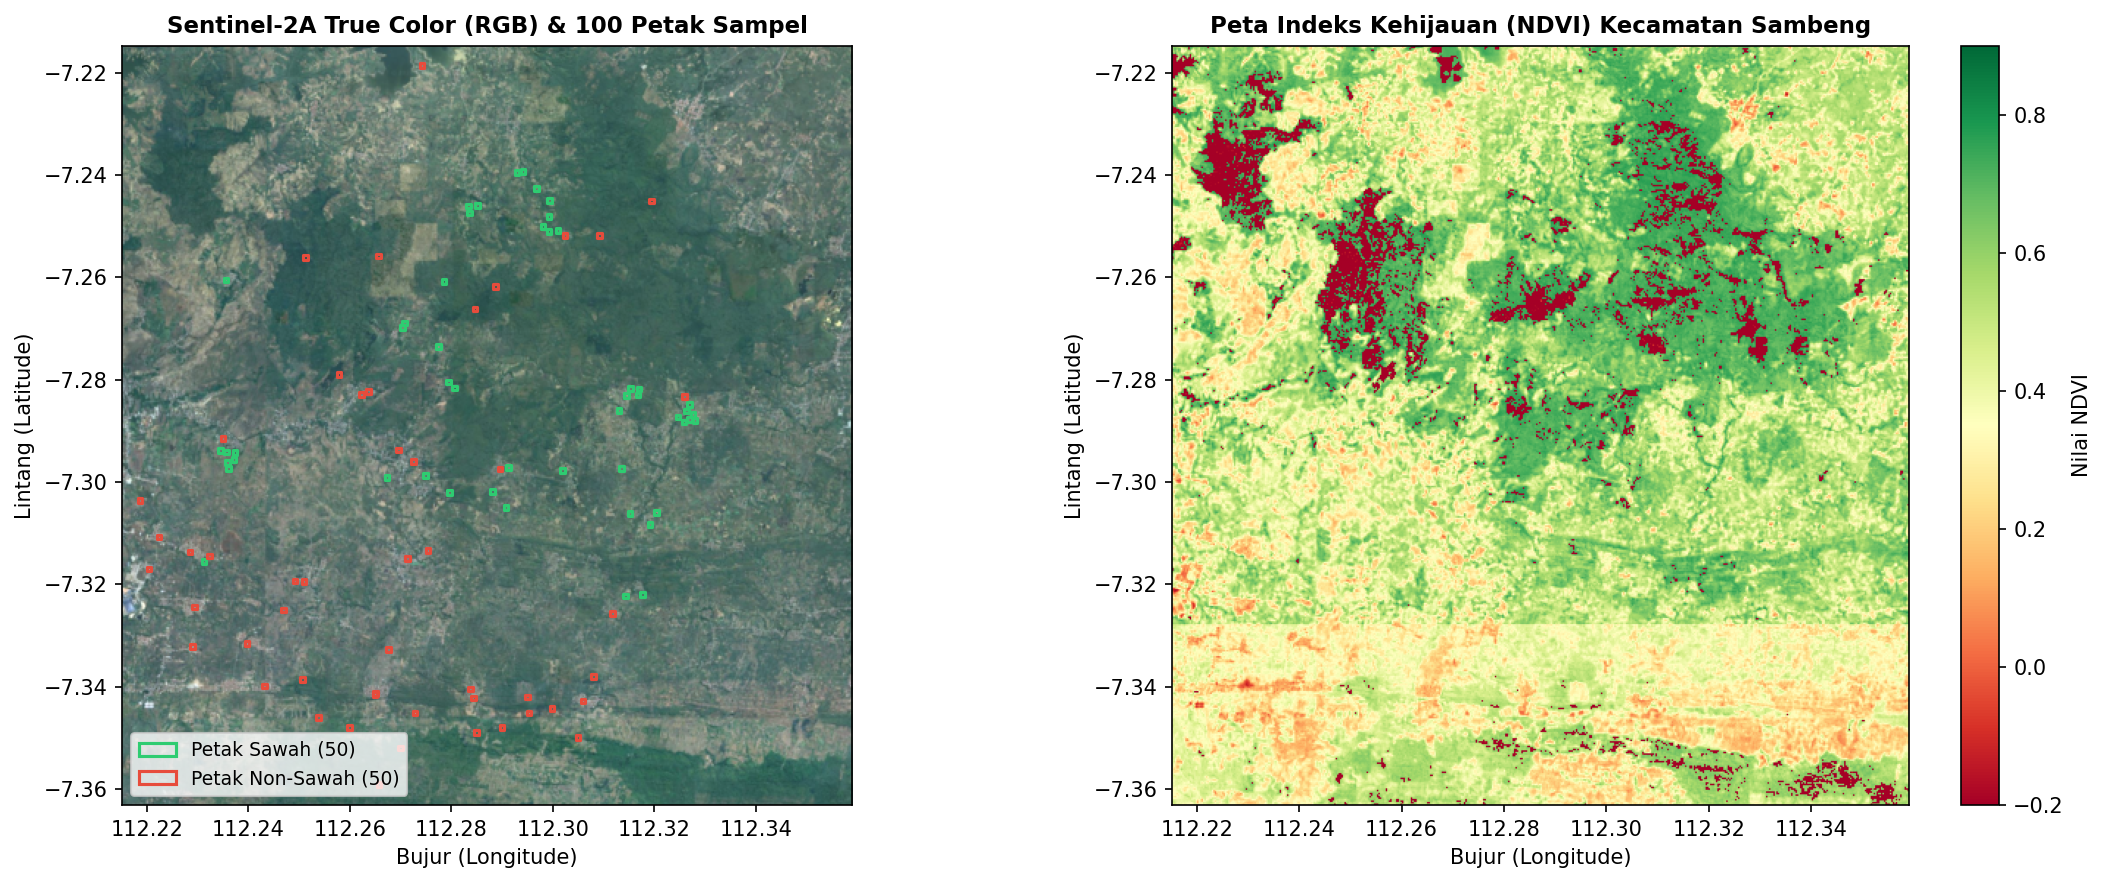

In [9]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

tif_path = 'sentinel2_sambeng.tif'

# Memuat citra satelit Sentinel-2A multi-band riil resolusi tinggi Kecamatan Sambeng
with rasterio.open(tif_path) as src:
    b2_blue = src.read(1)
    b3_green = src.read(2)
    b4_red = src.read(3)
    b8_nir = src.read(4)
    transform = src.transform
    width, height = src.width, src.height
    bounds = src.bounds

print(f"Citra Satelit Sentinel-2A GeoTIFF Berhasil Dimuat: {tif_path}")
print(f"- Dimensi Grid : {width} x {height} piksel")
print(f"- Rentang Kanal: Blue (DN {b2_blue.min()} - {b2_blue.max()}), Green (DN {b3_green.min()} - {b3_green.max()}), Red (DN {b4_red.min()} - {b4_red.max()}), NIR (DN {b8_nir.min()} - {b8_nir.max()})")

# Hitung matriks indeks kehijauan vegetasi NDVI
b8_f = b8_nir.astype(float)
b4_f = b4_red.astype(float)
ndvi_matrix = (b8_f - b4_f) / (b8_f + b4_f + 1e-6)

# Visualisasi Eksplorasi: Komposit RGB dan Peta Indeks Kehijauan NDVI
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Komposit True Color RGB (Band 4, Band 3, Band 2)
rgb = np.dstack([b4_red / b4_red.max(), b3_green / b3_green.max(), b2_blue / b2_blue.max()])
axes[0].imshow(rgb, extent=[minx, maxx, miny, maxy])
gdf_samples[gdf_samples['class'] == 1].plot(ax=axes[0], facecolor='none', edgecolor='#2ecc71', linewidth=1.5)
gdf_samples[gdf_samples['class'] == 0].plot(ax=axes[0], facecolor='none', edgecolor='#e74c3c', linewidth=1.5)
axes[0].set_title("Sentinel-2A True Color (RGB) & 100 Petak Sampel", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Bujur (Longitude)")
axes[0].set_ylabel("Lintang (Latitude)")
import matplotlib.patches as mpatches
p_sw = mpatches.Patch(edgecolor='#2ecc71', facecolor='none', linewidth=1.5, label='Petak Sawah (50)')
p_nsw = mpatches.Patch(edgecolor='#e74c3c', facecolor='none', linewidth=1.5, label='Petak Non-Sawah (50)')
axes[0].legend(handles=[p_sw, p_nsw], loc='lower left', fontsize=9)

# Peta Indeks Kehijauan NDVI
im_ndvi = axes[1].imshow(ndvi_matrix, cmap='RdYlGn', extent=[minx, maxx, miny, maxy], vmin=-0.2, vmax=0.9)
axes[1].set_title("Peta Indeks Kehijauan (NDVI) Kecamatan Sambeng", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Bujur (Longitude)")
axes[1].set_ylabel("Lintang (Latitude)")
plt.colorbar(im_ndvi, ax=axes[1], label='Nilai NDVI')

plt.tight_layout()
plt.show()


---
## Langkah 5: Ekstraksi Nilai Spektral Titik Sampel (`extract` Scikit-EO)

Mengikuti alur fungsi `extract()` pada pustaka **`scikit-eo`**, respon spektral pada titik pusat (*centroid*) setiap petak sampel diekstrak langsung dari kanal raster Sentinel-2A untuk membangun dataset tabular:
- `band_blue`, `band_green`, `band_red`, `band_nir`
- `ndvi` $\rightarrow$ Indeks biomassa vegetasi sawah
- `ndwi` $\rightarrow$ Indeks kebasahan lahan
- `class` $\rightarrow$ Label target (1 = Sawah, 0 = Non-Sawah)


In [11]:
# Ekstraksi respon spektral pada titik pusat (centroid) 100 petak sampel menggunakan rasterio.sample
with rasterio.open(tif_path) as src:
    coords = [(geom.centroid.x, geom.centroid.y) for geom in gdf_samples.geometry]
    sampled_values = list(src.sample(coords))

# Membentuk DataFrame spektral tabular (dikonversi ke tipe float untuk kalkulasi indeks presisi)
df_features = pd.DataFrame(sampled_values, columns=['band_blue', 'band_green', 'band_red', 'band_nir'], dtype=float)
df_features['id'] = gdf_samples['id'].values
df_features['label'] = gdf_samples['label'].values
df_features['tipe'] = gdf_samples['tipe'].values
df_features['class'] = gdf_samples['class'].values

# Hitung indeks spektral NDVI dan NDWI langsung dari respon spektral
df_features['ndvi'] = (df_features['band_nir'] - df_features['band_red']) / (df_features['band_nir'] + df_features['band_red'] + 1e-6)
df_features['ndwi'] = (df_features['band_green'] - df_features['band_nir']) / (df_features['band_green'] + df_features['band_nir'] + 1e-6)

print("Data Spektral Berhasil Diekstrak (100 Petak Sampel):")
print(df_features[['id', 'label', 'class', 'tipe', 'band_red', 'band_nir', 'ndvi', 'ndwi']].head(10))

print("\nPerbandingan Rata-Rata Respon Spektral Berdasarkan Kelas:")
print(df_features.groupby('label')[['band_blue', 'band_green', 'band_red', 'band_nir', 'ndvi', 'ndwi']].mean())


Data Spektral Berhasil Diekstrak (100 Petak Sampel):
   id  label  class             tipe  band_red  band_nir      ndvi      ndwi
0   1  Sawah      1  Petak Sawah #01    1055.0    3454.0  0.532047 -0.487191
1   2  Sawah      1  Petak Sawah #02    1676.0    2723.0  0.238009 -0.266806
2   3  Sawah      1  Petak Sawah #03    1181.0    3355.0  0.479277 -0.461874
3   4  Sawah      1  Petak Sawah #04    1170.0    2991.0  0.437635 -0.422931
4   5  Sawah      1  Petak Sawah #05    1653.0    2658.0  0.233125 -0.272075
5   6  Sawah      1  Petak Sawah #06    1078.0    3898.0  0.566720 -0.496353
6   7  Sawah      1  Petak Sawah #07    1331.0    3037.0  0.390568 -0.379201
7   8  Sawah      1  Petak Sawah #08     963.0    3762.0  0.592381 -0.505703
8   9  Sawah      1  Petak Sawah #09     756.0    4181.0  0.693741 -0.605915
9  10  Sawah      1  Petak Sawah #10    1066.0    3411.0  0.523788 -0.482399

Perbandingan Rata-Rata Respon Spektral Berdasarkan Kelas:
             band_blue  band_green  band_

---
## Langkah 6: Pelatihan Model Machine Learning Random Forest (MLA Scikit-EO)

Sesuai metodologi pada modul klasifikasi terbimbing (*Supervised Classification*) `scikit-eo`:
1. Dataset dibagi menjadi **80% data latih (*training*)** dan **20% data uji (*testing*)**.
2. Algoritma **Random Forest Classifier** dilatih menggunakan kombinasi fitur spektral (`band_blue`, `band_green`, `band_red`, `band_nir`, `ndvi`, `ndwi`).
3. Evaluasi kuantitatif diukur melalui:
   - **Overall Accuracy**
   - **Cohen's Kappa Index**
   - **Confusion Matrix**
   - **Feature Importance**


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, classification_report

feature_names = ['band_blue', 'band_green', 'band_red', 'band_nir', 'ndvi', 'ndwi']
X = df_features[feature_names]
y = df_features['class']

# Pembagian data 80% train / 20% test (stratified by class)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Pelatihan Model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prediksi data uji
y_pred = rf_model.predict(X_test)

# Evaluasi Metrik Klasifikasi
overall_accuracy = accuracy_score(y_test, y_pred)
kappa_index = cohen_kappa_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("="*60)
print(f"HASIL EVALUASI RANDOM FOREST (2 KELAS: SAWAH VS NON-SAWAH)")
print("="*60)
print(f"Overall Accuracy : {overall_accuracy * 100:.2f}%")
print(f"Kappa Index      : {kappa_index:.4f}")
print("\nConfusion Matrix:")
df_conf = pd.DataFrame(conf_matrix, 
                       index=['Aktual: Non-Sawah', 'Aktual: Sawah'], 
                       columns=['Prediksi: Non-Sawah', 'Prediksi: Sawah'])
print(df_conf)

# Simpan matriks konfusi ke CSV (alur standar scikit-eo)
df_conf.to_csv('confusion_matrix_sawah.csv', sep=';')
print("\nMatriks konfusi tersimpan di: confusion_matrix_sawah.csv")

print("\nLaporan Klasifikasi Terperinci:")
print(classification_report(y_test, y_pred, target_names=['Non-Sawah', 'Sawah']))

# Tingkat Kepentingan Fitur (Feature Importance)
df_importance = pd.DataFrame({
    'Fitur': feature_names,
    'Tingkat Kepentingan': rf_model.feature_importances_
}).sort_values('Tingkat Kepentingan', ascending=False)

print("\nTingkat Kepentingan Fitur (Feature Importance):")
print(df_importance.to_string(index=False))


HASIL EVALUASI RANDOM FOREST (2 KELAS: SAWAH VS NON-SAWAH)
Overall Accuracy : 95.00%
Kappa Index      : 0.9000

Confusion Matrix:
                   Prediksi: Non-Sawah  Prediksi: Sawah
Aktual: Non-Sawah                   10                0
Aktual: Sawah                        1                9

Matriks konfusi tersimpan di: confusion_matrix_sawah.csv

Laporan Klasifikasi Terperinci:
              precision    recall  f1-score   support

   Non-Sawah       0.91      1.00      0.95        10
       Sawah       1.00      0.90      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20


Tingkat Kepentingan Fitur (Feature Importance):
     Fitur  Tingkat Kepentingan
  band_nir             0.376319
      ndwi             0.252014
      ndvi             0.131532
 band_blue             0.097747
  band_red             0.086875
band_green             0.055512


---
## Langkah 7: Prediksi Seluruh Citra & Visualisasi Komparasi Peta Klasifikasi

Model Random Forest diterapkan ke setiap piksel pada citra satelit Sentinel-2A untuk memetakan seluruh tutupan lahan Kecamatan Sambeng.
Hasil disimpan sebagai **GeoTIFF (`klasifikasi_sawah_sambeng.tif`)** yang kompatibel langsung dengan **QGIS**, dan divisualisasikan berdampingan (*side-by-side*) persis seperti alur pustaka **`scikit-eo`**:
- **Kiri:** *Image in Surface Reflectance* (Komposit citra satelit Sentinel-2A).
- **Kanan:** *Classification map* (Peta klasifikasi tutupan lahan 2 kelas).


Peta Klasifikasi GeoTIFF Berhasil Disimpan dengan Palet Warna: klasifikasi_sawah_sambeng.tif
Estimasi Tutupan Lahan Kecamatan Sambeng:
- Sawah      : 148882 piksel (59.55%)
- Non-Sawah  : 101118 piksel (40.45%)


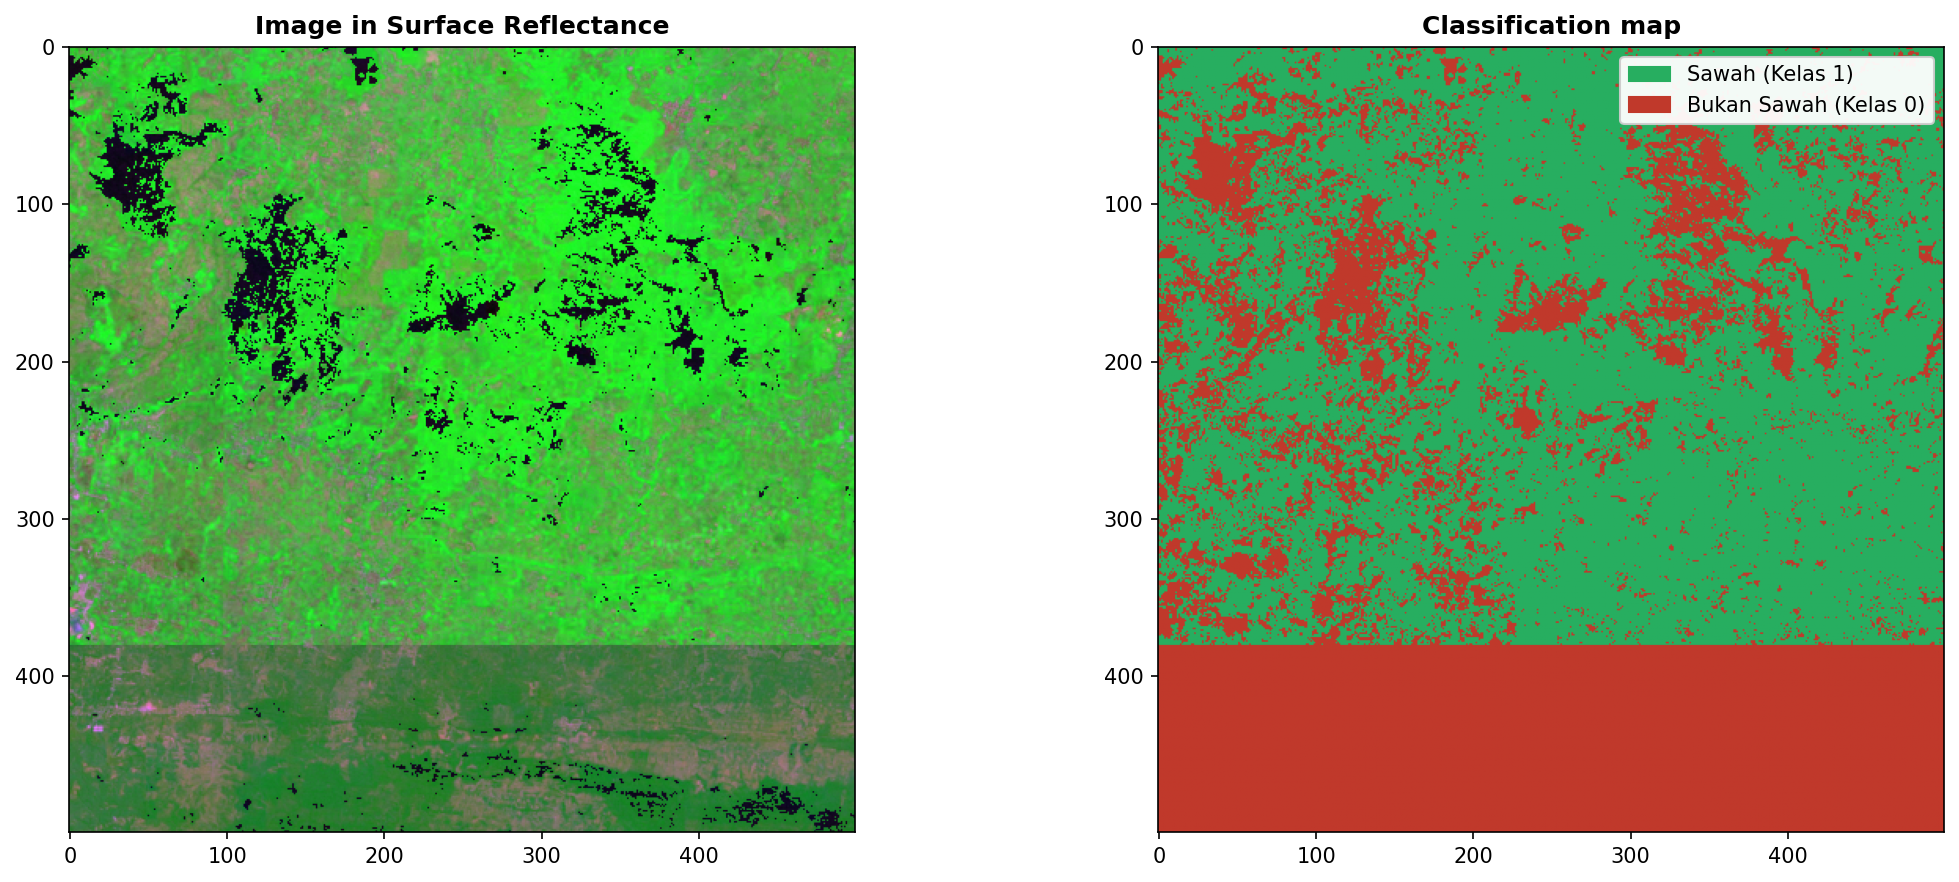

In [15]:
# Membaca seluruh piksel raster citra satelit
with rasterio.open(tif_path) as src:
    all_b2 = src.read(1).astype(float)
    all_b3 = src.read(2).astype(float)
    all_b4 = src.read(3).astype(float)
    all_b8 = src.read(4).astype(float)
    profile = src.profile

# Hitung NDVI & NDWI untuk seluruh grid piksel
all_ndvi = (all_b8 - all_b4) / (all_b8 + all_b4 + 1e-6)
all_ndwi = (all_b3 - all_b8) / (all_b3 + all_b8 + 1e-6)

# Bentuk DataFrame piksel untuk inferensi model
pixels_df = pd.DataFrame({
    'band_blue': all_b2.ravel(),
    'band_green': all_b3.ravel(),
    'band_red': all_b4.ravel(),
    'band_nir': all_b8.ravel(),
    'ndvi': all_ndvi.ravel(),
    'ndwi': all_ndwi.ravel()
})

# Prediksi klasifikasi 2 kelas untuk seluruh wilayah
class_pred_1d = rf_model.predict(pixels_df)
# Memastikan dimensi raster sesuai
with rasterio.open(tif_path) as src:
    h_ras, w_ras = src.height, src.width
classification_map = class_pred_1d.reshape((h_ras, w_ras)).astype(np.uint8)

# Simpan Peta Klasifikasi ke format GeoTIFF (QGIS Ready)
output_class_tif = 'klasifikasi_sawah_sambeng.tif'
profile.update(dtype=rasterio.uint8, count=1, nodata=255)

with rasterio.open(output_class_tif, 'w', **profile) as dst:
    dst.write(classification_map, 1)
    dst.set_band_description(1, 'LandCover_Class_Sawah_vs_NonSawah')
    dst.write_colormap(1, {
        0: (231, 76, 60, 255),   # Merah: Bukan Sawah
        1: (39, 174, 96, 255)    # Hijau: Sawah
    })

print(f"Peta Klasifikasi GeoTIFF Berhasil Disimpan dengan Palet Warna: {output_class_tif}")

# Hitung Estimasi Luas Tutupan Sawah vs Non-Sawah
total_pixels = classification_map.size
sawah_pixels = np.sum(classification_map == 1)
non_sawah_pixels = np.sum(classification_map == 0)

print(f"Estimasi Tutupan Lahan Kecamatan Sambeng:")
print(f"- Sawah      : {sawah_pixels} piksel ({sawah_pixels / total_pixels * 100:.2f}%)")
print(f"- Non-Sawah  : {non_sawah_pixels} piksel ({non_sawah_pixels / total_pixels * 100:.2f}%)")

# =============================================================================
# Visualisasi Side-by-Side Sesuai Format Tutorial Scikit-EO
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 0: Image in Surface Reflectance
# Komposit Pertanian: Red=Band 4, Green=Band 8 (NIR), Blue=Band 2 (Blue)
# Vegetasi sawah tampak hijau segar, badan air biru, dan pemukiman/tanah merah muda/cokelat
r_disp = (all_b4 - all_b4.min()) / (all_b4.max() - all_b4.min())
g_disp = (all_b8 - all_b8.min()) / (all_b8.max() - all_b8.min())
b_disp = (all_b2 - all_b2.min()) / (all_b2.max() - all_b2.min())
rgb_composite = np.dstack([r_disp, g_disp, b_disp])

axes[0].imshow(rgb_composite)
axes[0].set_title("Image in Surface Reflectance", fontsize=12, fontweight='bold')
axes[0].grid(False)

# Subplot 1: Classification map
cmap_palette = plt.matplotlib.colors.ListedColormap(['#c0392b', '#27ae60'])
im_class = axes[1].imshow(classification_map, cmap=cmap_palette)
axes[1].set_title("Classification map", fontsize=12, fontweight='bold')
axes[1].grid(False)

# Legenda Warna Kategori Tutupan Lahan
patch_sawah = mpatches.Patch(color='#27ae60', label='Sawah (Kelas 1)')
patch_non = mpatches.Patch(color='#c0392b', label='Bukan Sawah (Kelas 0)')
axes[1].legend(handles=[patch_sawah, patch_non], loc='upper right', framealpha=0.95)

plt.tight_layout()
plt.show()


---
## Langkah 8: Visualisasi Peta Interaktif Geospasial (Google Satellite & Folium)

Peta interaktif berbasis Leaflet menyajikan 100 petak sampel kotak-kotak observasi (50 Sawah dan 50 Non-Sawah) dengan dukungan **citra satelit resolusi tinggi**:
- 🛰️ **Google Satellite (Hybrid):** Citra satelit Google resolusi tinggi lengkap dengan nama jalan, toponimi desa, dan kontur wilayah.
- 🌍 **Google Satellite:** Citra satelit optik murni tanpa label.
- 🗺️ **Esri World Imagery:** Citra satelit global resolusi tinggi dari Esri ArcGIS.
- 🗺️ **OpenStreetMap:** Peta jalan standar kartografi.

**Lapisan Data:**
- 🌾 **Peta Hasil Klasifikasi Random Forest:** Lapisan tematik tutupan lahan hasil prediksi model (Sawah berwarna hijau dan Bukan Sawah berwarna merah/oranye transparan) yang diproyeksikan langsung di atas citra satelit.
- 🟢 **Petak Hijau Kotak-Kotak:** 50 Petak Sawah (Kelas 1) pada hamparan persawahan riil.
- 🔴 **Petak Merah Kotak-Kotak:** 50 Petak Bukan Sawah (Kelas 0) pada atap pemukiman desa, aliran Kali Lamong, waduk, dan hutan perbukitan.
- Dilengkapi dengan batas poligon resmi Kecamatan Sambeng dan kontrol lapisan (*LayerControl*).


Peta interaktif sampel sawah tersimpan di: peta_sampel_sawah_sambeng.html



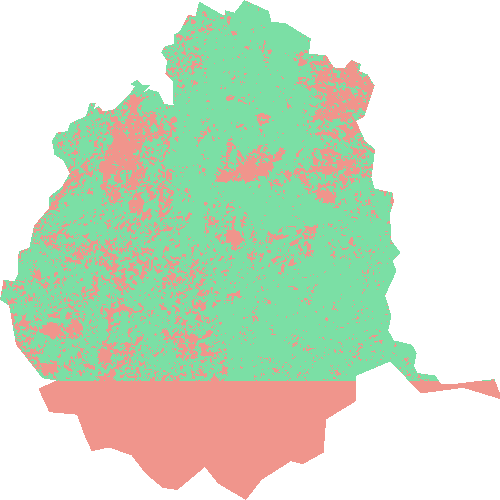

In [17]:
import folium
from folium.raster_layers import ImageOverlay
import rasterio

center_lat = (miny + maxy) / 2
center_lon = (minx + maxx) / 2

# Inisialisasi Peta Interaktif
map_samples = folium.Map(location=[center_lat, center_lon], zoom_start=12, tiles=None)

# 1. Basemap Google Satellite (Hybrid) - Default Utama
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Satellite Hybrid',
    name='🛰️ Google Satellite (Hybrid)',
    overlay=False,
    control=True
).add_to(map_samples)

# 2. Basemap Google Satellite (Murni)
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google Satellite',
    name='🌍 Google Satellite',
    overlay=False,
    control=True
).add_to(map_samples)

# 3. Basemap Esri World Imagery
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='🗺️ Esri Satellite',
    overlay=False,
    control=True
).add_to(map_samples)

# 4. Basemap OpenStreetMap
folium.TileLayer(
    tiles='OpenStreetMap',
    name='🗺️ OpenStreetMap',
    overlay=False,
    control=True
).add_to(map_samples)

# 5. Layer Overlay: Hasil Klasifikasi Random Forest (Sawah vs Non-Sawah)
with rasterio.open('klasifikasi_sawah_sambeng_clipped.tif') as src_class:
    class_data = src_class.read(1)
    ras_bounds = src_class.bounds

# Bentuk matriks RGBA tematik
class_rgba = np.zeros((class_data.shape[0], class_data.shape[1], 4), dtype=np.uint8)
# Sawah (Nilai 1): Hijau Segar (#2ecc71 / RGBA 46, 204, 113, 160)
class_rgba[class_data == 1] = [46, 204, 113, 160]
# Bukan Sawah (Nilai 0): Merah/Oranye (#e74c3c / RGBA 231, 76, 60, 150)
class_rgba[class_data == 0] = [231, 76, 60, 150]
# Di Luar Sambeng (Nilai 255): Transparan
class_rgba[class_data == 255] = [0, 0, 0, 0]

img_bounds = [[ras_bounds.bottom, ras_bounds.left], [ras_bounds.top, ras_bounds.right]]

ImageOverlay(
    name='🌾 Hasil Klasifikasi Sawah (Random Forest)',
    image=class_rgba,
    bounds=img_bounds,
    opacity=0.85,
    interactive=True,
    show=True
).add_to(map_samples)

# Tambahkan Batas Poligon Resmi Kecamatan Sambeng
folium.GeoJson(
    gdf_aoi.to_json(),
    name='Batas Wilayah Sambeng',
    style_function=lambda x: {
        'fillColor': 'none',
        'color': '#f1c40f',
        'weight': 3,
        'dashArray': '6, 6'
    }
).add_to(map_samples)

# Layer 50 Petak Sawah Kotak-Kotak (Hijau)
fg_sawah = folium.FeatureGroup(name='🟢 50 Petak Sawah (Kelas 1)', show=True)
for _, row in gdf_samples[gdf_samples['class'] == 1].iterrows():
    popup_text = f"""<b>ID:</b> {row['id']}<br>
<b>Kelas:</b> Sawah<br>
<b>Tipe:</b> {row['tipe']}<br>
<b>Koordinat:</b> {row['lat']:.5f}, {row['lon']:.5f}"""
    folium.GeoJson(
        row['geometry'],
        style_function=lambda x: {
            'fillColor': '#2ecc71',
            'color': '#27ae60',
            'weight': 2,
            'fillOpacity': 0.65
        },
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=f"Petak Sawah #{row['id']}: {row['tipe']}"
    ).add_to(fg_sawah)

# Layer 50 Petak Non-Sawah Kotak-Kotak (Merah)
fg_non_sawah = folium.FeatureGroup(name='🔴 50 Petak Bukan Sawah (Kelas 0)', show=True)
for _, row in gdf_samples[gdf_samples['class'] == 0].iterrows():
    popup_text = f"""<b>ID:</b> {row['id']}<br>
<b>Kelas:</b> Bukan Sawah<br>
<b>Tipe:</b> {row['tipe']}<br>
<b>Koordinat:</b> {row['lat']:.5f}, {row['lon']:.5f}"""
    folium.GeoJson(
        row['geometry'],
        style_function=lambda x: {
            'fillColor': '#e74c3c',
            'color': '#c0392b',
            'weight': 2,
            'fillOpacity': 0.65
        },
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=f"Petak Non-Sawah #{row['id']}: {row['tipe']}"
    ).add_to(fg_non_sawah)

fg_sawah.add_to(map_samples)
fg_non_sawah.add_to(map_samples)

# Legenda Peta Tematik
legend_html = '''
<div style="position: fixed; 
     bottom: 30px; left: 30px; width: 280px; z-index:9999; font-size:12px;
     background-color: white; opacity: 0.94; padding: 12px; border-radius: 8px; 
     border: 2px solid #ccc; box-shadow: 2px 2px 8px rgba(0,0,0,0.3);">
     <b>Legenda Klasifikasi Sambeng</b><br>
     <div style="margin-top: 6px;">
        <i style="background:#2ecc71; opacity:0.8; width:16px; height:16px; float:left; margin-right:8px; border:1px solid #27ae60;"></i> Klasifikasi: Sawah (Padi Aktif)<br>
        <i style="background:#e74c3c; opacity:0.8; width:16px; height:16px; float:left; margin-right:8px; border:1px solid #c0392b; margin-top:4px;"></i> Klasifikasi: Bukan Sawah<br>
        <hr style="margin: 6px 0; border:0; border-top:1px solid #ddd;">
        <i style="border:2px solid #27ae60; background:none; width:14px; height:14px; float:left; margin-right:8px;"></i> 50 Petak Sampel Sawah<br>
        <i style="border:2px solid #c0392b; background:none; width:14px; height:14px; float:left; margin-right:8px; margin-top:4px;"></i> 50 Petak Sampel Non-Sawah<br>
        <small style="color: #666; display: block; margin-top: 6px;">Gunakan panel kanan atas untuk ganti basemap & layer.</small>
     </div>
</div>
'''
map_samples.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl(collapsed=False).add_to(map_samples)

# Simpan ke berkas HTML mandiri
peta_sawah_html = 'peta_sampel_sawah_sambeng.html'
map_samples.save(peta_sawah_html)
print(f"Peta interaktif sampel sawah tersimpan di: {peta_sawah_html}")

map_samples


---
## Langkah 9: Kesimpulan Akhir & Panduan Lengkap Buka di QGIS

### Panduan Membuka & Menampilkan Petak di QGIS dengan Google Satellite:
1. **Membuka Petak Sampel Kotak-Kotak:**
   - Ekstrak berkas `sampel_sawah_sambeng.zip` ke sebuah folder.
   - Buka aplikasi **QGIS**, lalu tarik (*drag & drop*) file `sampel_sawah_sambeng.shp` ke dalam kanvas peta QGIS.
   - **Fitur Auto-Style (.qml):** Karena di dalam folder tersebut terdapat file `sampel_sawah_sambeng.qml`, QGIS akan **secara otomatis menampilkan petak kotak-kotak berwarna hijau (Sawah) dan merah (Bukan Sawah)** lengkap dengan teks label langsung di atas setiap petak!

2. **Menambahkan Basemap Google Satellite di QGIS:**
   - Di panel **Browser** QGIS (sebelah kiri), klik kanan **XYZ Tiles** $\rightarrow$ pilih **New Connection**.
   - Masukkan Name: `Google Satellite` dan URL: `https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}`.
   - Klik **OK**, lalu tarik (*drag & drop*) layer `Google Satellite` ke kanvas peta di bawah layer `sampel_sawah_sambeng`.
   - Anda akan melihat petak-petak hijau persis berada di atas area sawah nyata, dan petak-petak merah berada tepat di atas pemukiman desa, aliran sungai Kali Lamong, waduk, dan hutan perbukitan!

3. **Membuka Raster Klasifikasi Sentinel-2A di QGIS:**
   - Tarik (*drag & drop*) file **`klasifikasi_sawah_sambeng.tif`** ke QGIS.
   - Layer raster klasifikasi akan langsung menutupi seluruh Kecamatan Sambeng dengan pembagian 2 kelas yang jelas dan presisi.
